<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Aula_06/Pratica6Quest%C3%A3o4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

N = 4320 amostras | min = 121.8 | max = 547.4 | média = 339.5 | desvio padrão = 107.7


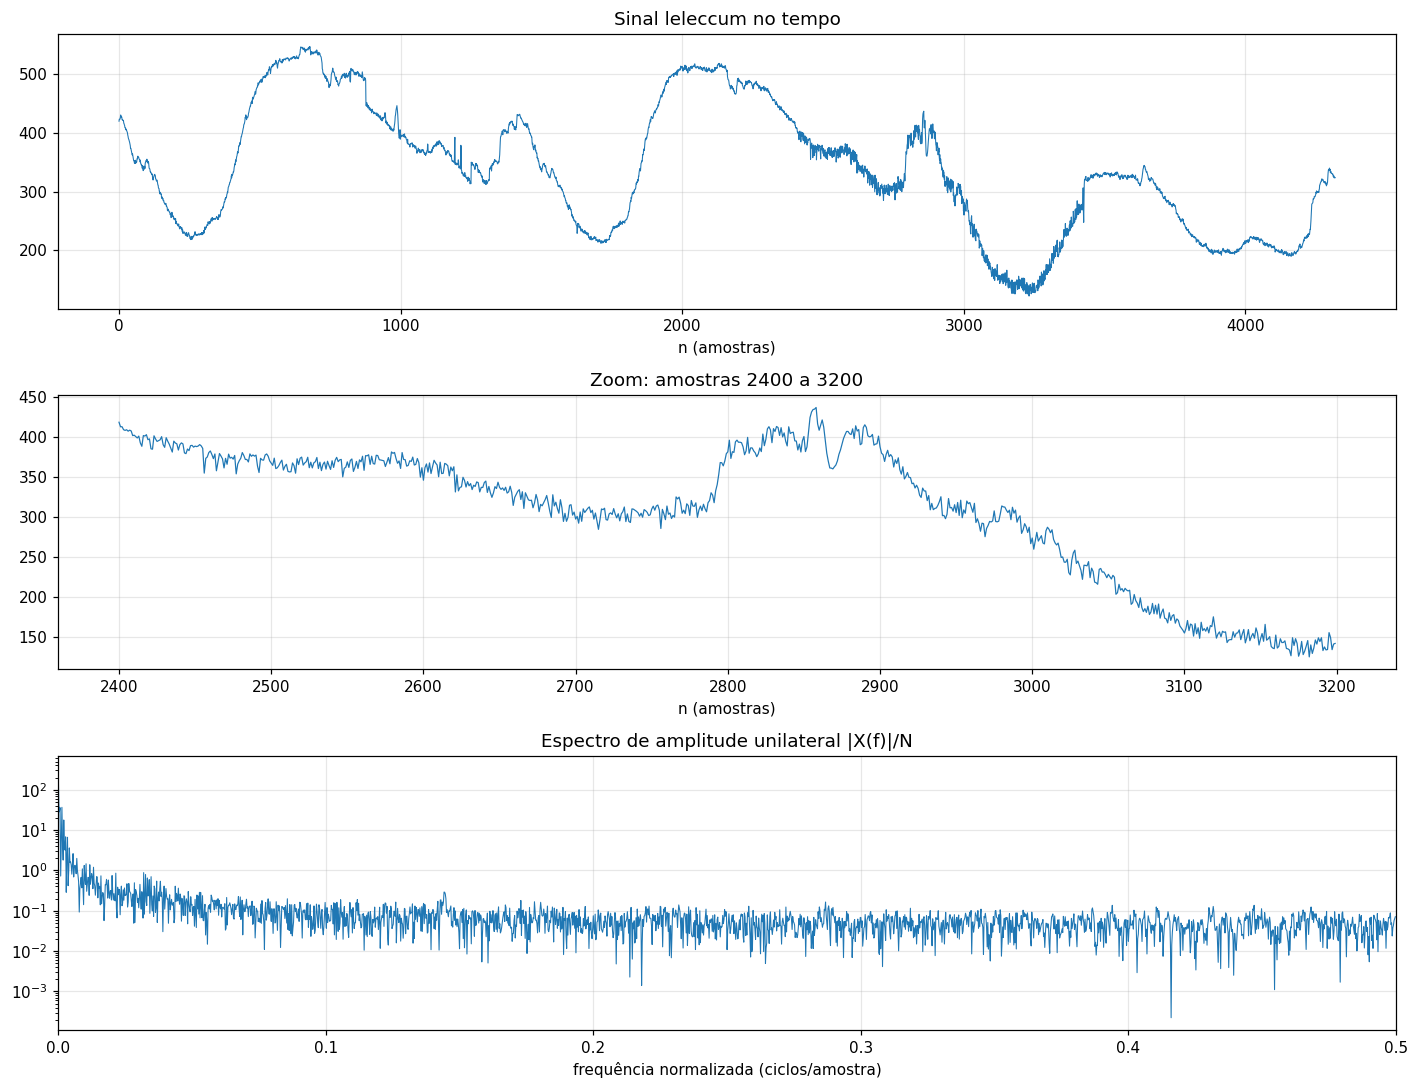

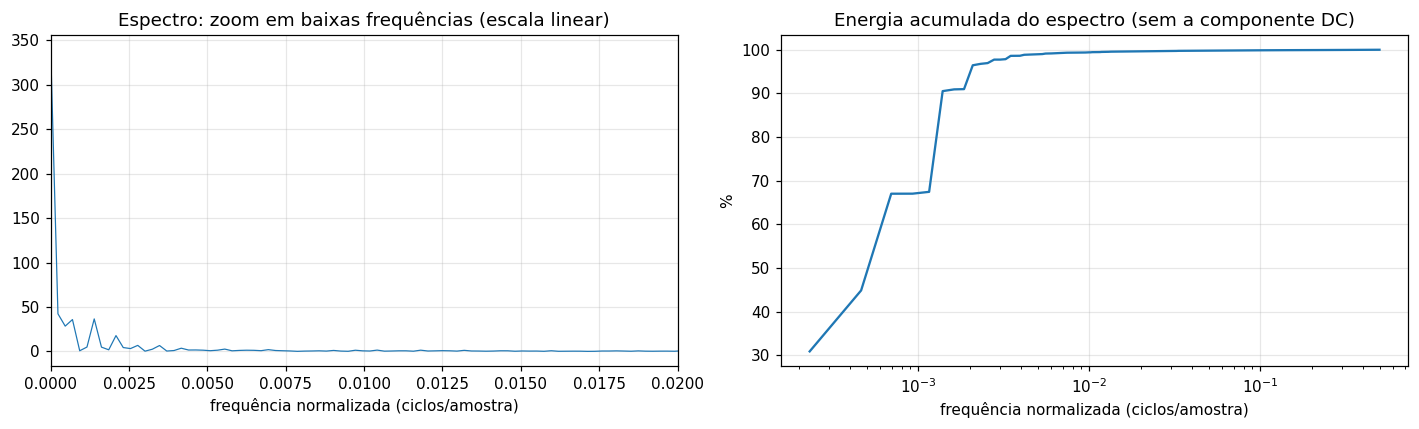

90.0% da energia (sem DC) abaixo de f = 0.0014 ciclos/amostra
99.0% da energia (sem DC) abaixo de f = 0.0053 ciclos/amostra
99.9% da energia (sem DC) abaixo de f = 0.1426 ciclos/amostra

Wavelet: db4 | ortogonal: True | momentos nulos: 4

Análise passa-baixas (h0)  (8 coeficientes)
  h[0] = -0.0105974018
  h[1] =  0.0328830117
  h[2] =  0.0308413818
  h[3] = -0.1870348117
  h[4] = -0.0279837694
  h[5] =  0.6308807679
  h[6] =  0.7148465706
  h[7] =  0.2303778133
  soma =  1.414214   energia =  1.000000

Análise passa-altas (h1)  (8 coeficientes)
  h[0] = -0.2303778133
  h[1] =  0.7148465706
  h[2] = -0.6308807679
  h[3] = -0.0279837694
  h[4] =  0.1870348117
  h[5] =  0.0308413818
  h[6] = -0.0328830117
  h[7] = -0.0105974018
  soma =  0.000000   energia =  1.000000

Síntese passa-baixas (g0)  (8 coeficientes)
  h[0] =  0.2303778133
  h[1] =  0.7148465706
  h[2] =  0.6308807679
  h[3] = -0.0279837694
  h[4] = -0.1870348117
  h[5] =  0.0308413818
  h[6] =  0.0328830117
  h[7] = -0.01059

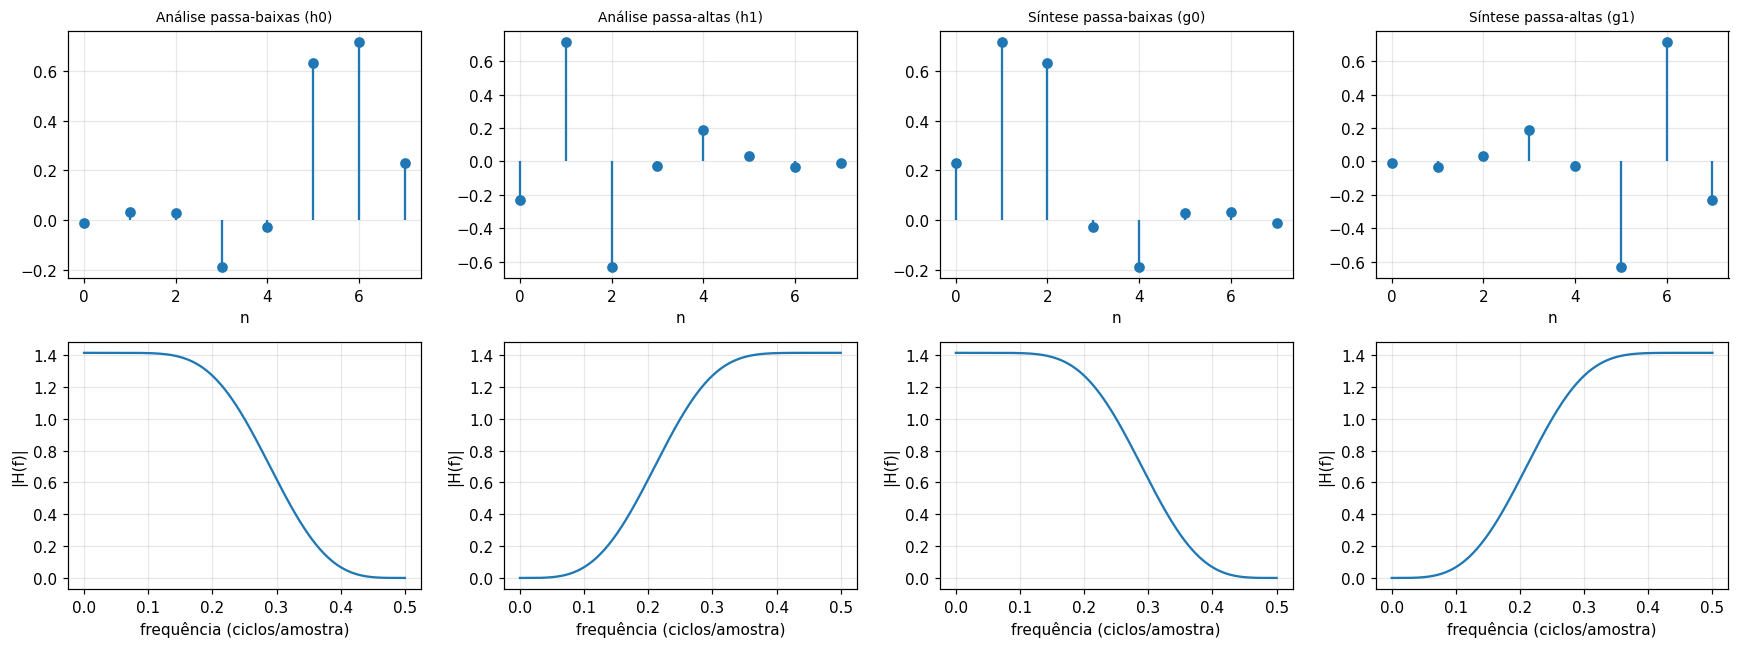

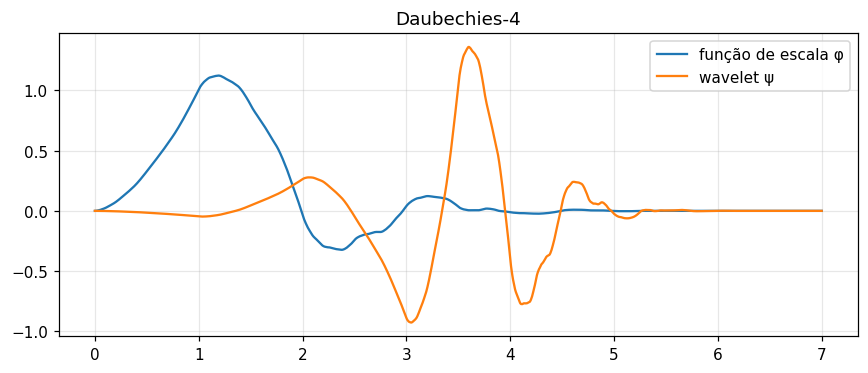

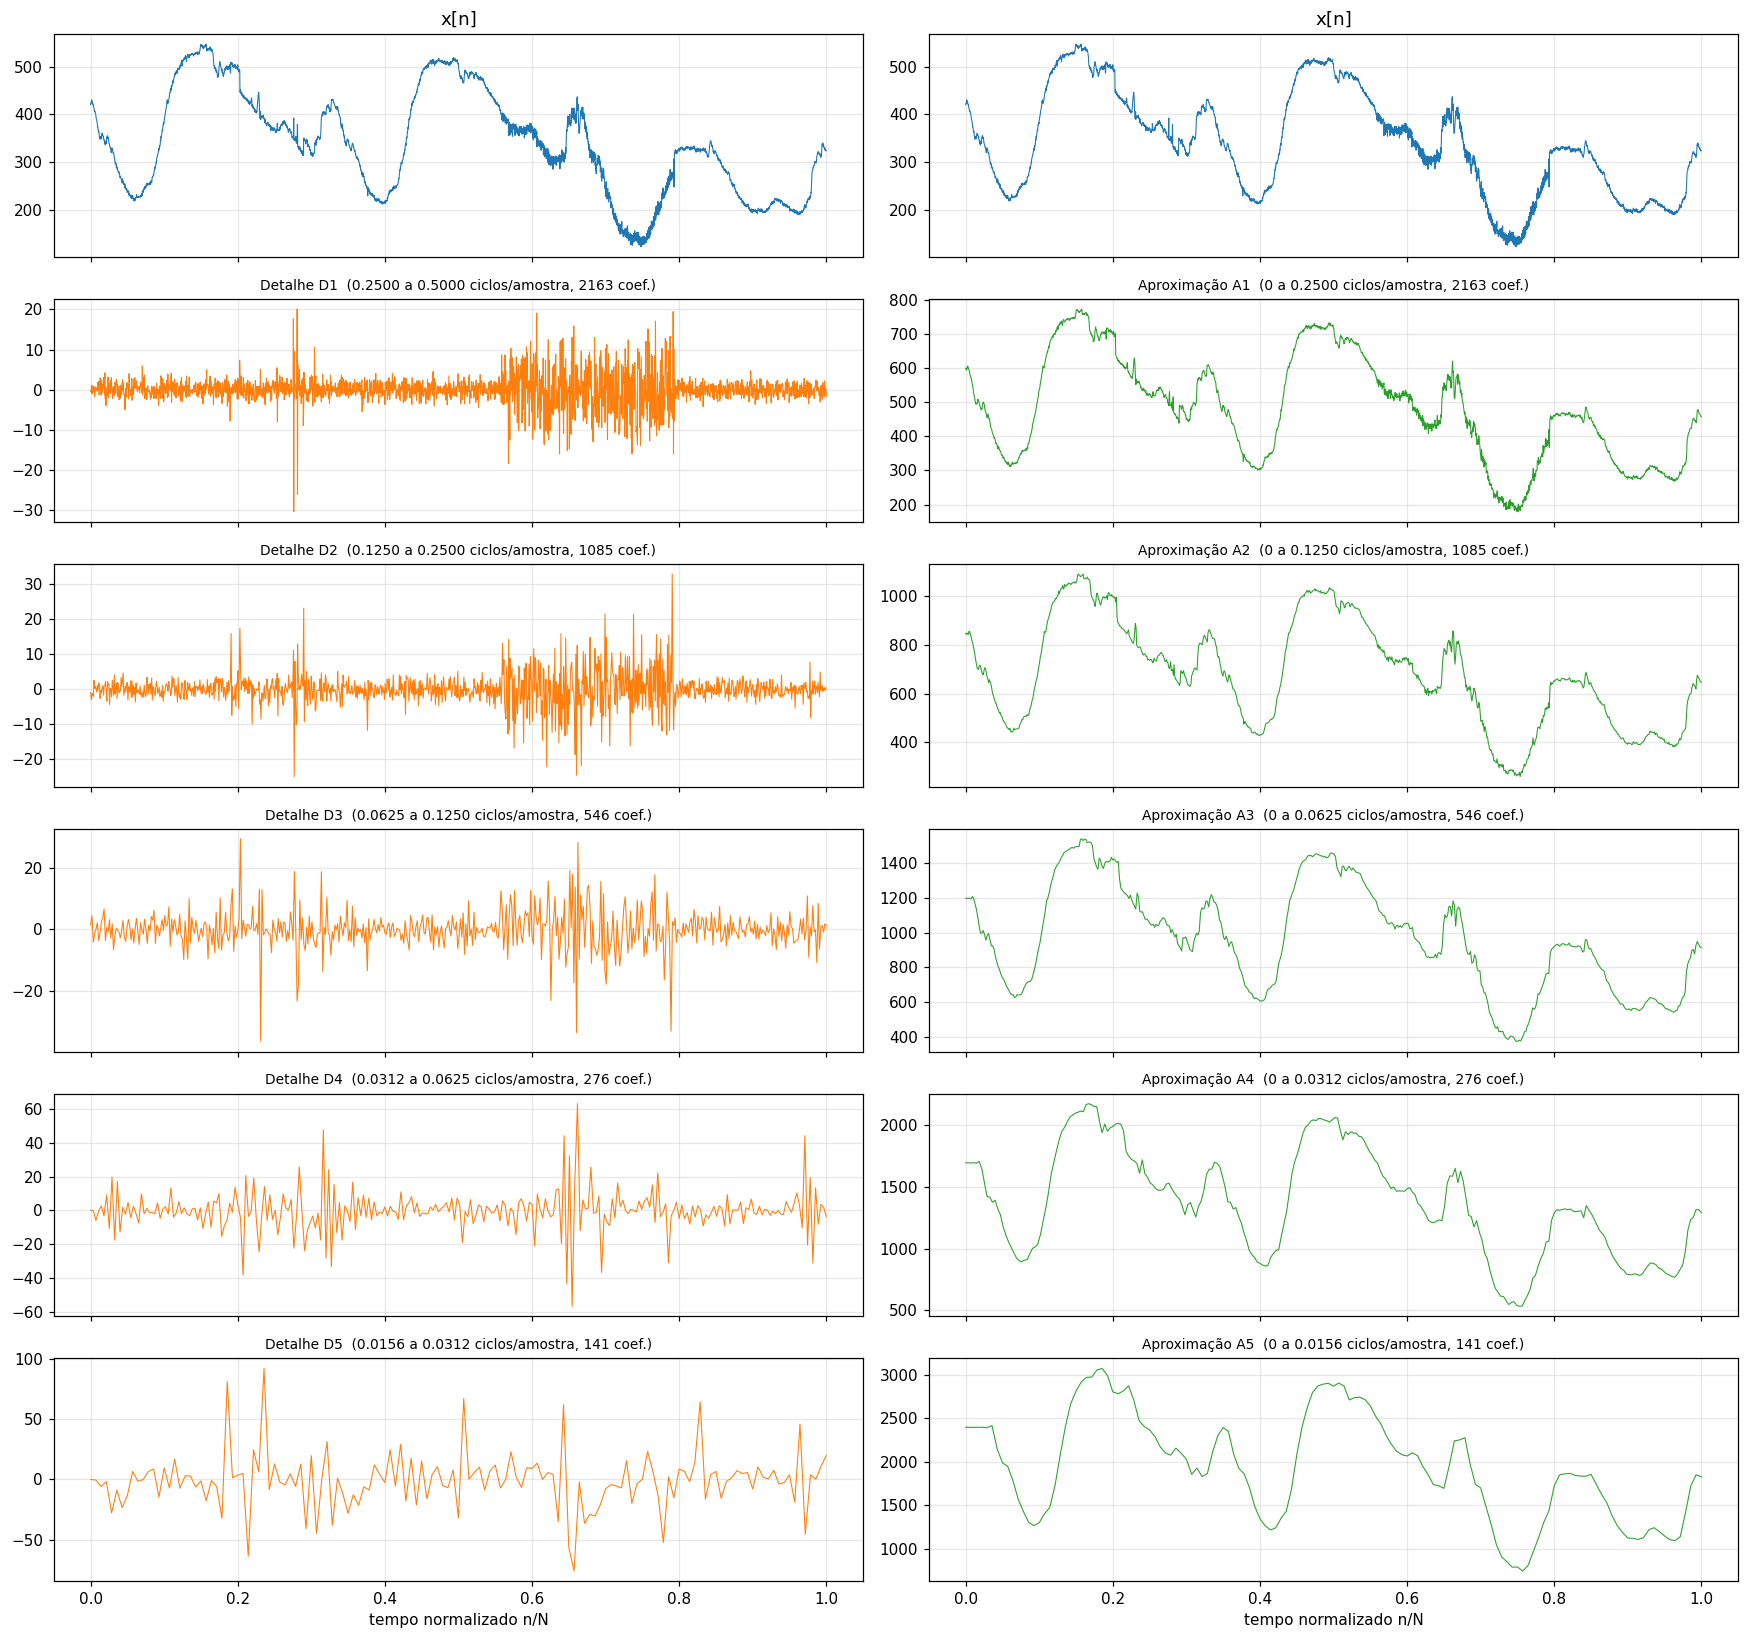


Energia dos coeficientes em cada sub-banda
  A5:   141 coef. | energia =  99.96777% | desvio padrão =   601.860
  D5:   141 coef. | energia =   0.01293% | desvio padrão =    23.051
  D4:   276 coef. | energia =   0.00685% | desvio padrão =    12.005
  D3:   546 coef. | energia =   0.00366% | desvio padrão =     6.236
  D2:  1085 coef. | energia =   0.00401% | desvio padrão =     4.634
  D1:  2163 coef. | energia =   0.00478% | desvio padrão =     3.584

Desvio padrão robusto (MAD/0,6745) dos detalhes: D1=1.87, D2=2.73, D3=4.02, D4=5.94, D5=11.76


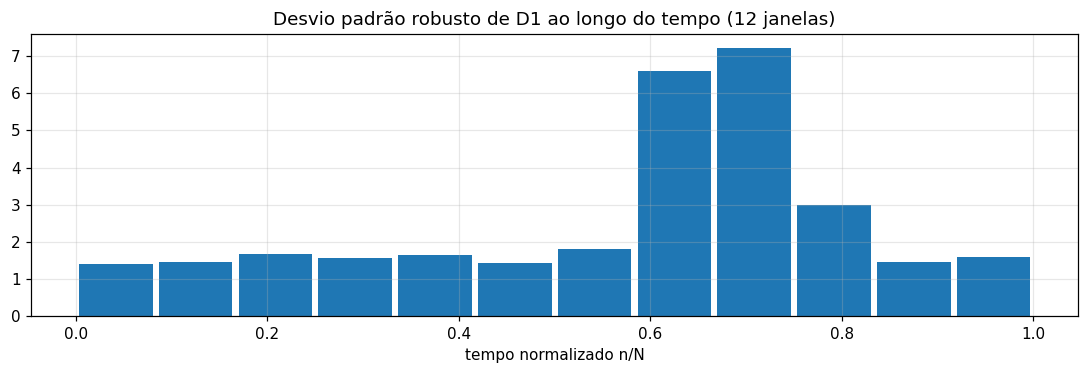


Ruído estimado em D1: sigma = 1.866 | limiar universal = sigma*sqrt(2 ln N) = 7.635


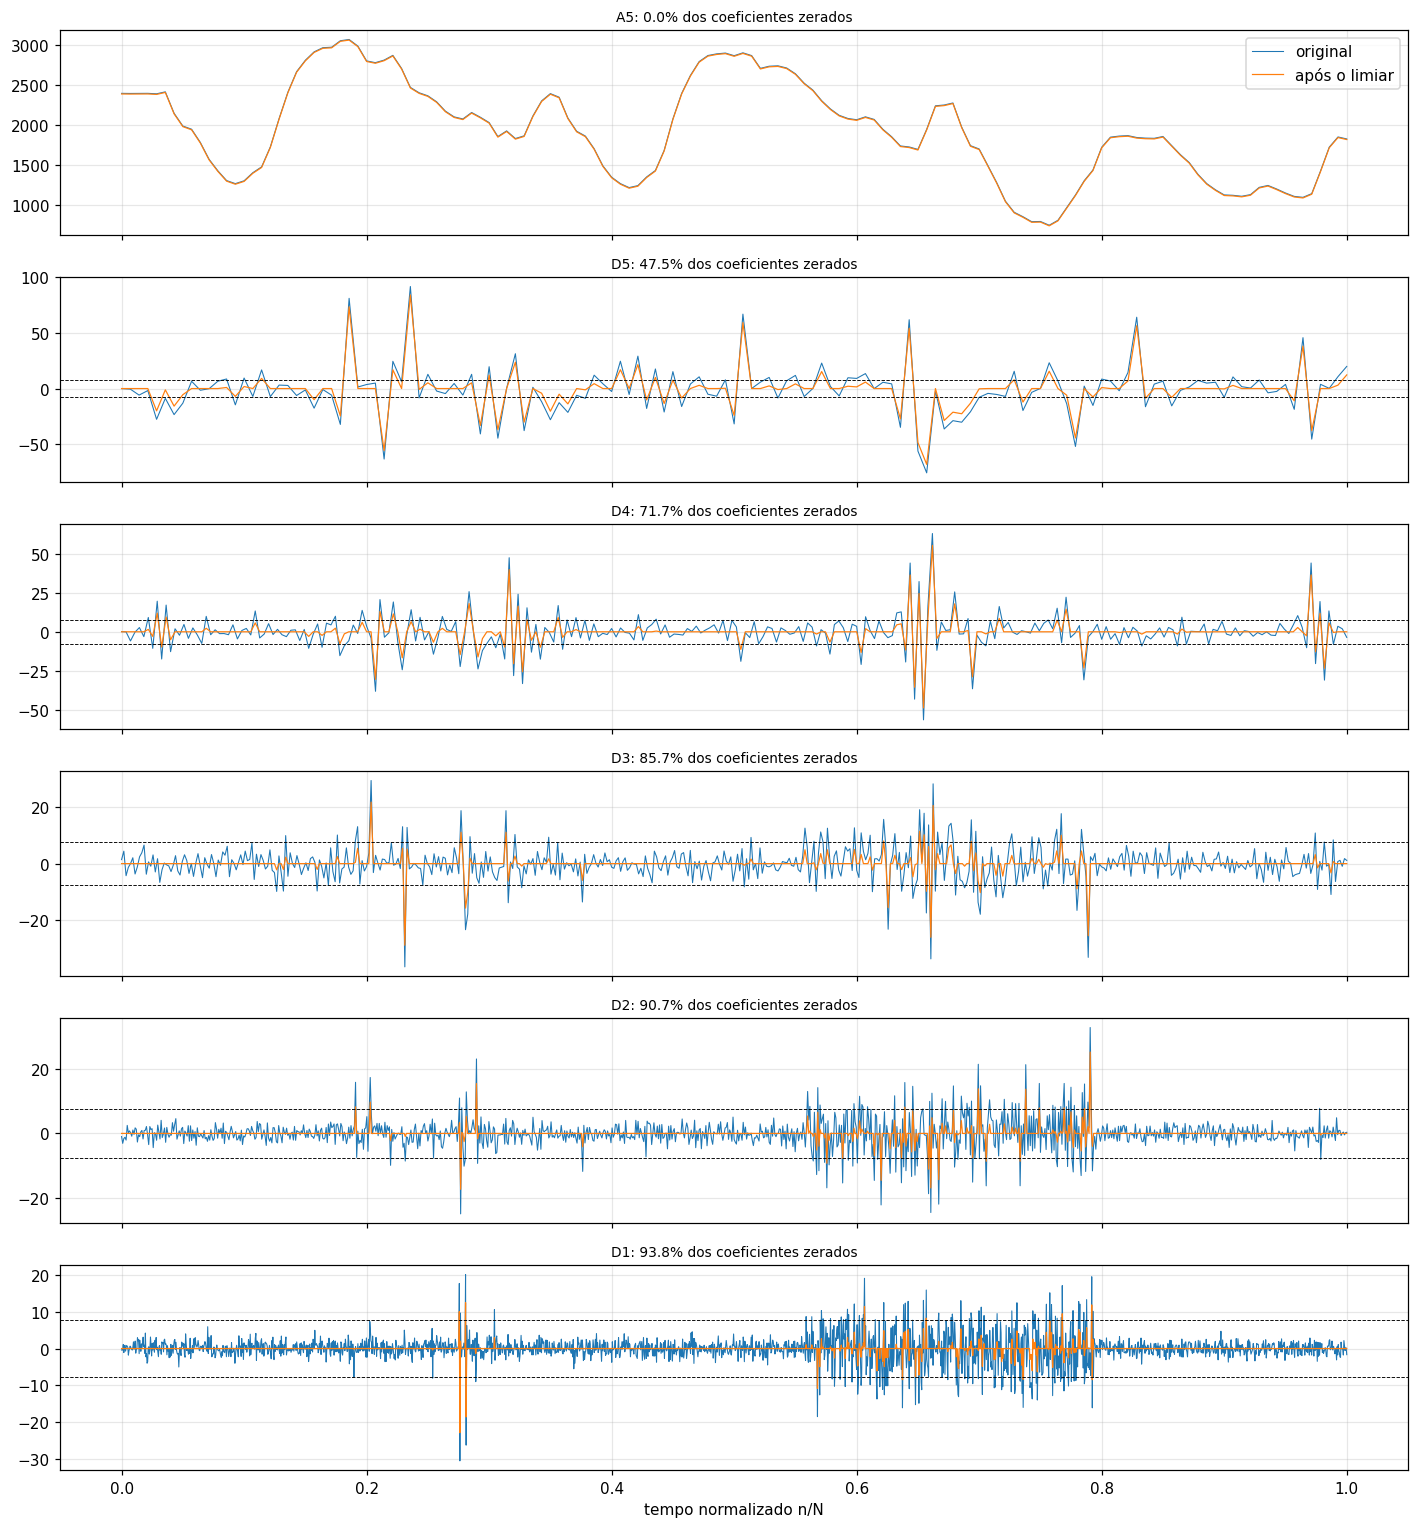


caso                       |  limiar | coef. zerados | média do resíduo | desvio do resíduo | variação total
-------------------------------------------------------------------------------------------------------------
sinal original             |       - |             - |                - |                 - |          14697
soft, 0,5·λu               |    3.82 |         76.3% |            0.001 |             2.346 |           7369
soft, 1·λu                 |    7.64 |         89.0% |            0.001 |             3.483 |           4983
soft, 2·λu                 |   15.27 |         96.9% |            0.001 |             4.630 |           3358
soft, 4·λu                 |   30.54 |         99.2% |            0.001 |             5.584 |           2915
hard, 1·λu                 |    7.64 |         89.0% |            0.001 |             2.426 |           9328
soft, 1·λu, incluindo A5   |    7.64 |         86.1% |            1.351 |             3.483 |           4983


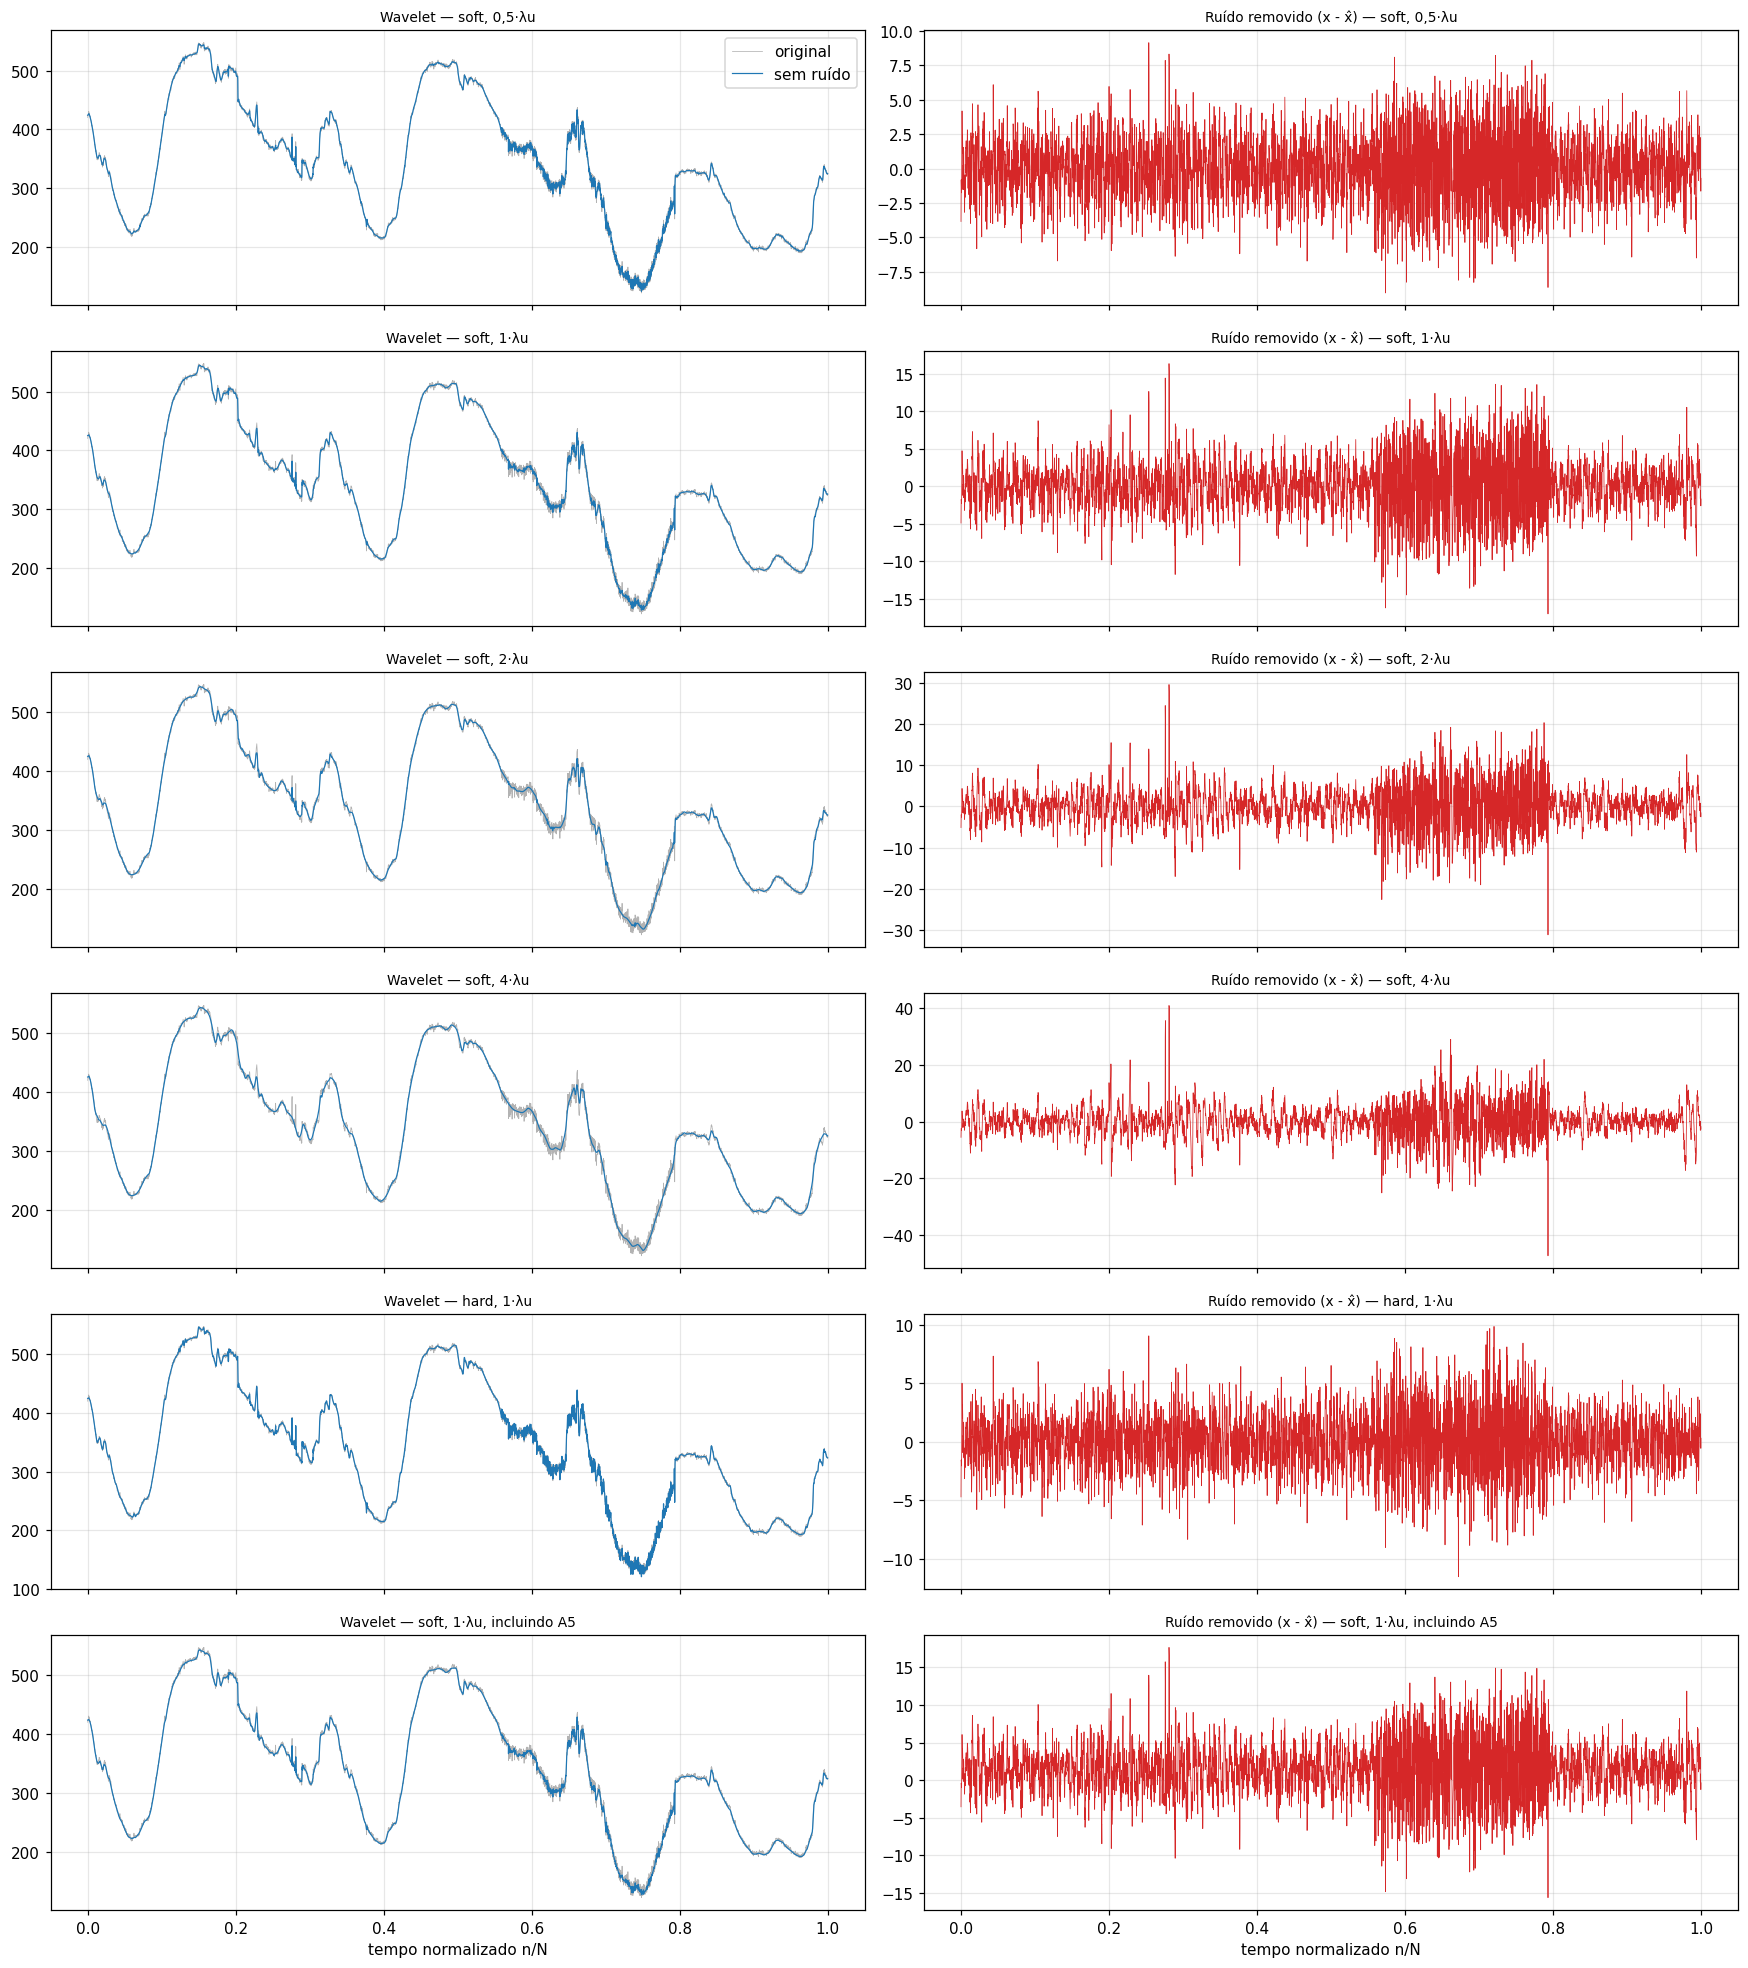

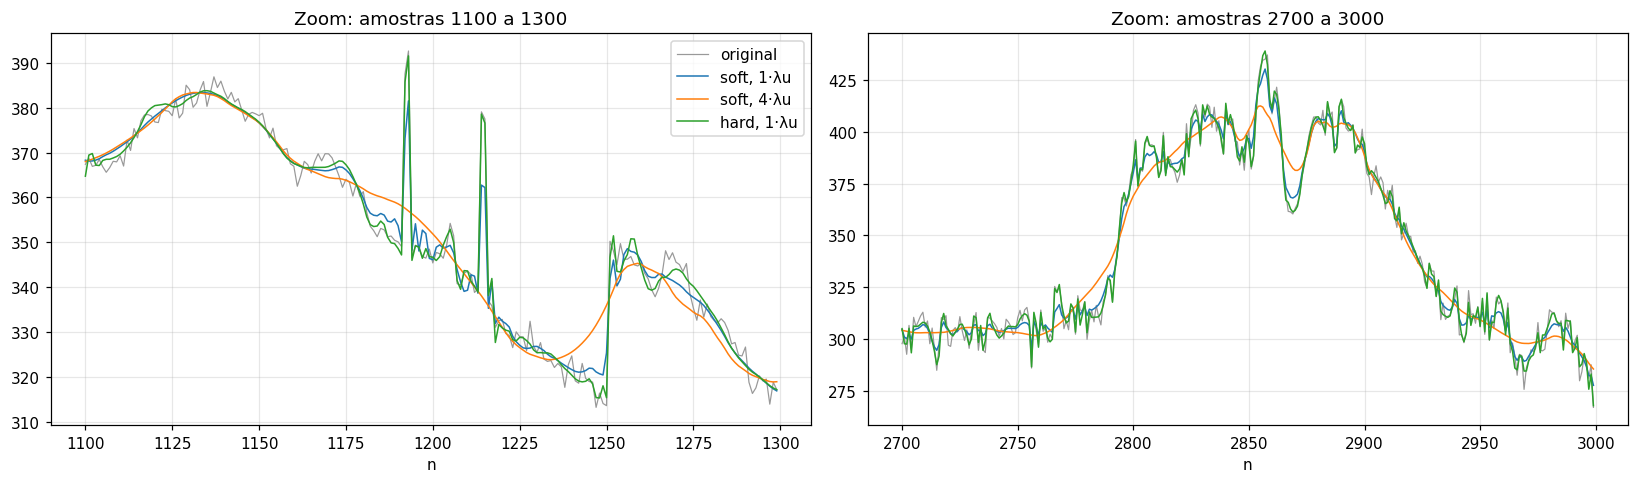


Nível mediano de |X[k]| na metade superior do espectro (piso de ruído): 202.7  (sigma*sqrt(N) = 122.6)

limiar DFT           |    valor | coef. mantidos | desvio do resíduo | variação total
-------------------------------------------------------------------------------------
1 x piso de ruído    |    202.7 |         63.26% |             1.245 |          14795
2 x piso de ruído    |    405.3 |         23.45% |             3.057 |          10766
4 x piso de ruído    |    810.6 |          8.08% |             4.475 |           4796
8 x piso de ruído    |   1621.2 |          3.73% |             5.722 |           3525


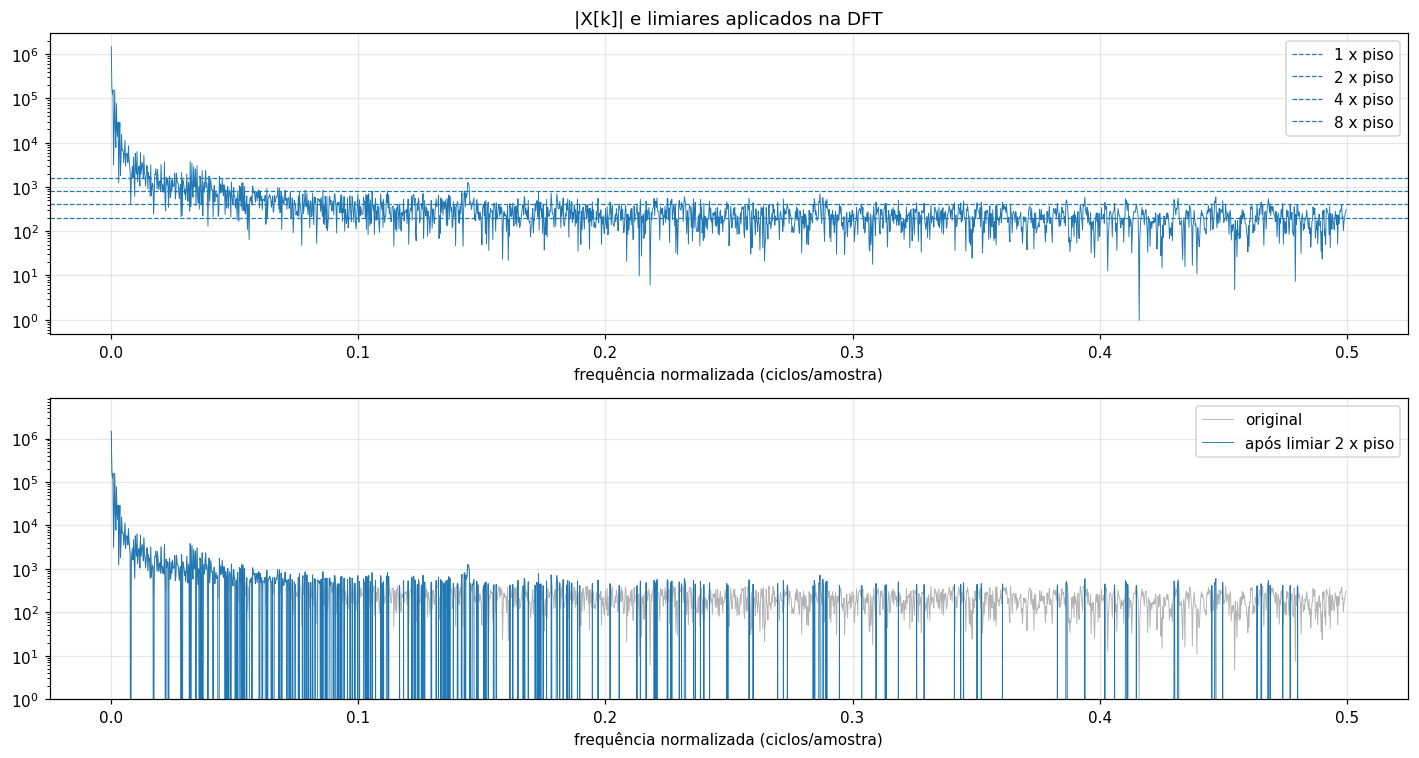

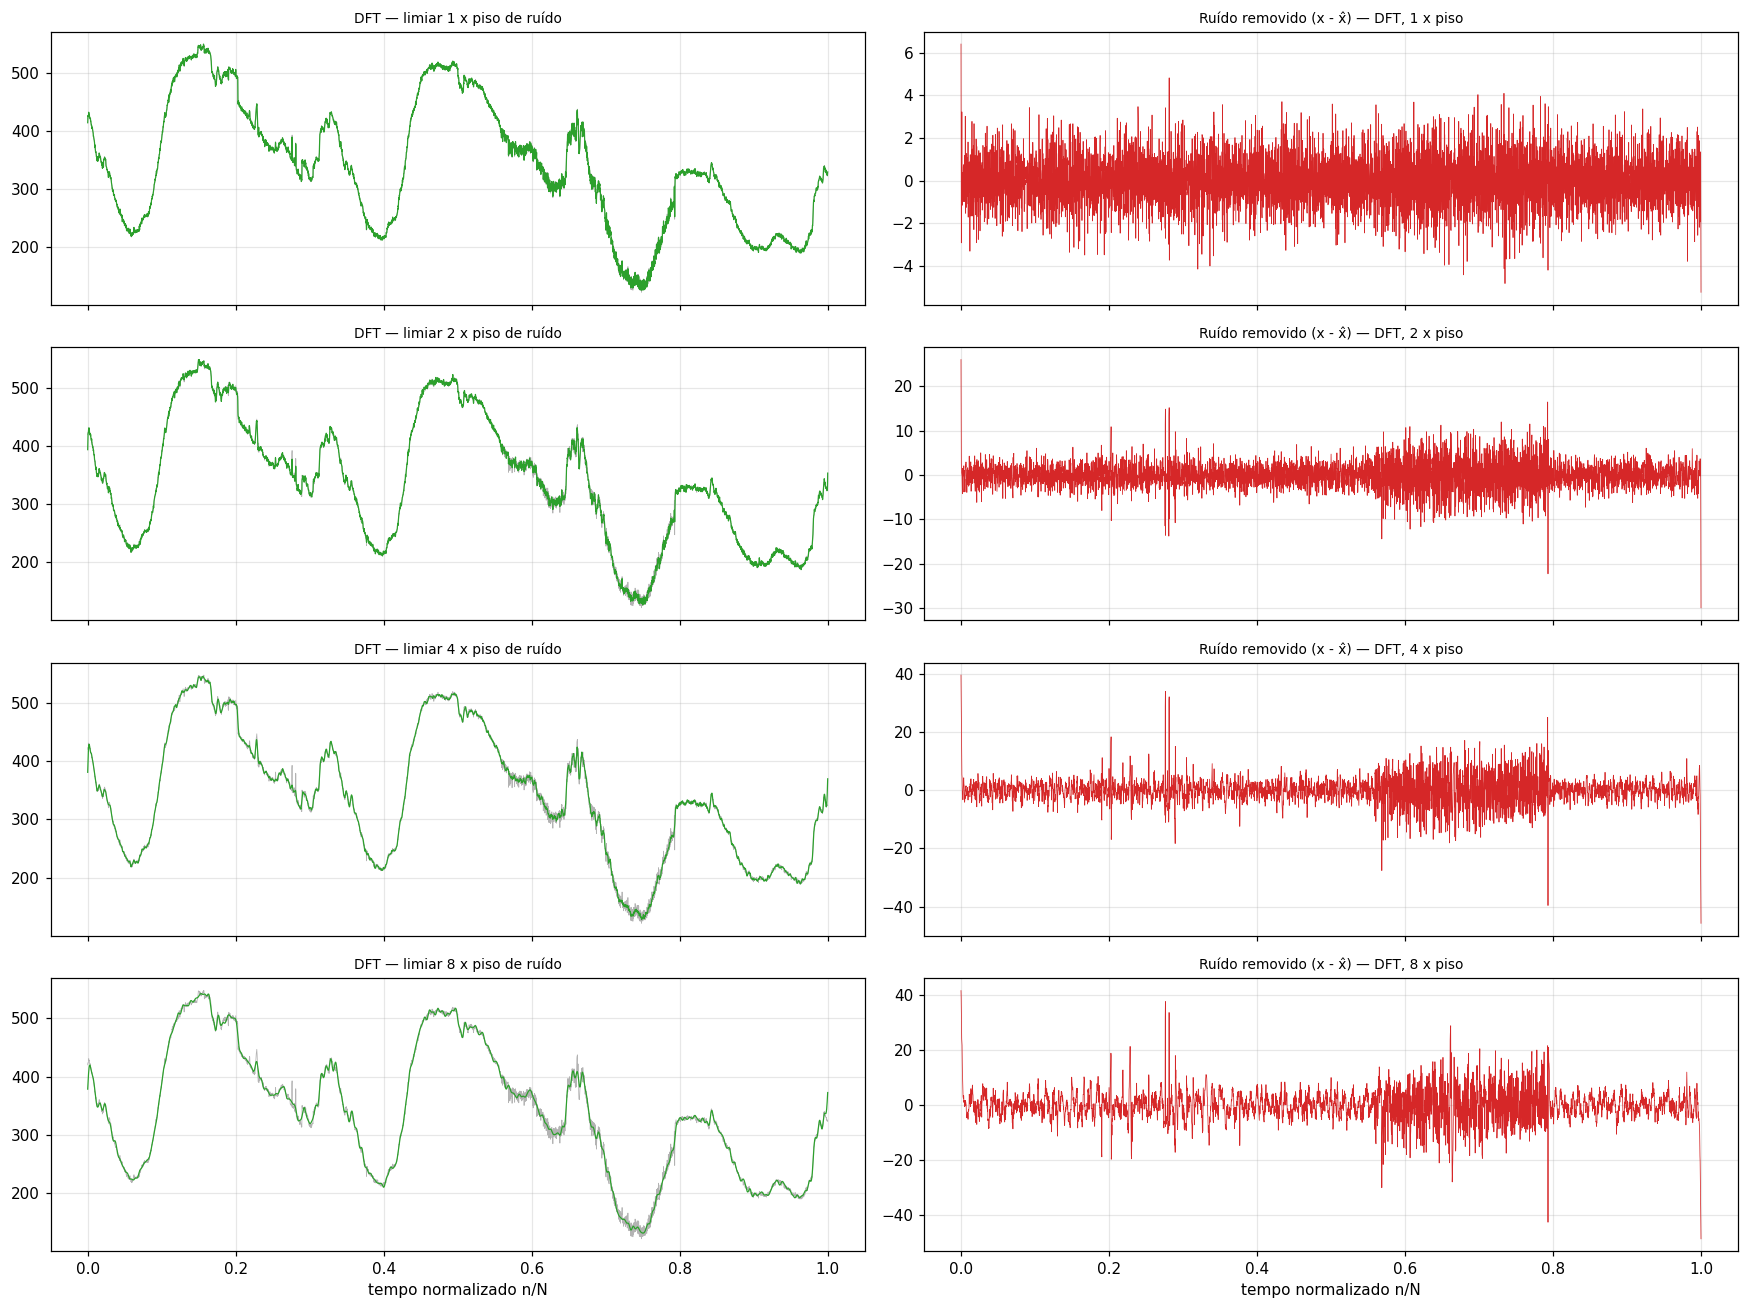

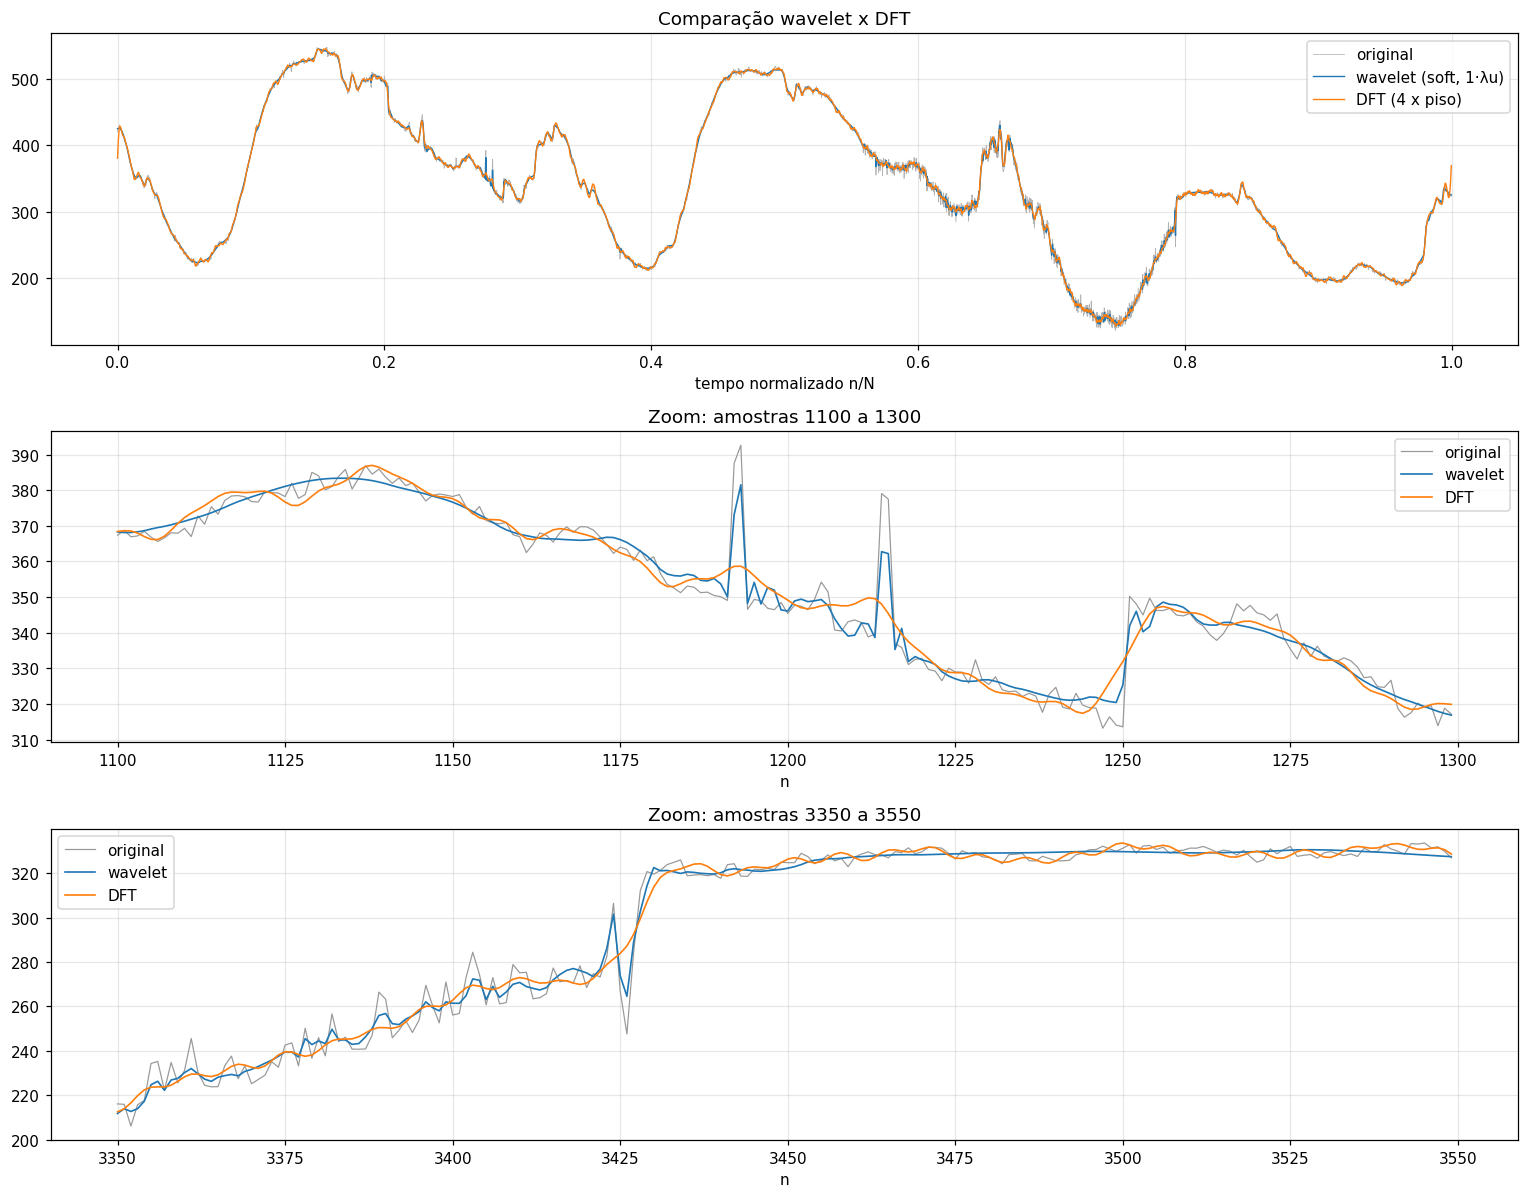


Comparação com suavização semelhante: wavelet soft 1·λu (variação total 4983) x DFT 4 x piso (variação total 4796)
  wavelet  amostras 1180-1210: maior salto entre amostras =   33.3 (original   46.1)
  wavelet  amostras 3400-3440: maior salto entre amostras =   27.7 (original   39.6)
  wavelet  oscilação do resíduo nas bordas (primeiras/últimas 30 amostras): 2.908
  DFT 1x   amostras 1180-1210: maior salto entre amostras =   39.9 (original   46.1)
  DFT 1x   amostras 3400-3440: maior salto entre amostras =   36.3 (original   39.6)
  DFT 1x   oscilação do resíduo nas bordas (primeiras/últimas 30 amostras): 1.716
  DFT 2x   amostras 1180-1210: maior salto entre amostras =   17.6 (original   46.1)
  DFT 2x   amostras 3400-3440: maior salto entre amostras =   17.5 (original   39.6)
  DFT 2x   oscilação do resíduo nas bordas (primeiras/últimas 30 amostras): 6.021
  DFT 4x   amostras 1180-1210: maior salto entre amostras =    1.9 (original   46.1)
  DFT 4x   amostras 3400-3440: maior salto 

In [ ]:
import os, subprocess, sys, urllib.request
try:
    import pywt
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'PyWavelets'])
    import pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.fft import fft, ifft, fftfreq

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

url = 'https://raw.githubusercontent.com/rafaelschaves/gele7317-proc-sin/master/data/leleccum.mat'
arquivo = next((p for p in ['leleccum.mat', 'data/leleccum.mat', 'gele7317-proc-sin/data/leleccum.mat'] if os.path.exists(p)), None)
if arquivo is None:
    arquivo = 'leleccum.mat'
    urllib.request.urlretrieve(url, arquivo)
x = np.ravel(loadmat(arquivo)['leleccum']).astype(float)
N = len(x)
n = np.arange(N)
tn = n / N


def calculate_spectrum(signal, sampling_frequency=1.0, single_sided=True):
    M = len(signal)
    yf = fft(signal)
    if single_sided:
        return fftfreq(M, 1 / sampling_frequency)[:M // 2], np.abs(yf[:M // 2]) / M
    return fftfreq(M, 1 / sampling_frequency), np.abs(yf) / M


print(f'N = {N} amostras | min = {x.min():.1f} | max = {x.max():.1f} | média = {x.mean():.1f} | desvio padrão = {x.std():.1f}')

f, X = calculate_spectrum(x)
fig, ax = plt.subplots(3, 1, figsize=(13, 10))
ax[0].plot(n, x, lw=0.7)
ax[0].set_title('Sinal leleccum no tempo')
ax[0].set_xlabel('n (amostras)')
ax[1].plot(n[2400:3200], x[2400:3200], lw=0.8)
ax[1].set_title('Zoom: amostras 2400 a 3200')
ax[1].set_xlabel('n (amostras)')
ax[2].semilogy(f, X, lw=0.7)
ax[2].set_title('Espectro de amplitude unilateral |X(f)|/N')
ax[2].set_xlabel('frequência normalizada (ciclos/amostra)')
ax[2].set_xlim(0, 0.5)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(f, X, lw=0.8)
ax[0].set_xlim(0, 0.02)
ax[0].set_title('Espectro: zoom em baixas frequências (escala linear)')
ax[0].set_xlabel('frequência normalizada (ciclos/amostra)')
E_acum = np.cumsum(X[1:] ** 2) / np.sum(X[1:] ** 2)
ax[1].semilogx(f[1:], 100 * E_acum)
ax[1].set_title('Energia acumulada do espectro (sem a componente DC)')
ax[1].set_xlabel('frequência normalizada (ciclos/amostra)')
ax[1].set_ylabel('%')
plt.tight_layout()
plt.show()
for p in [0.9, 0.99, 0.999]:
    print(f'{100*p:.1f}% da energia (sem DC) abaixo de f = {f[1:][np.argmax(E_acum >= p)]:.4f} ciclos/amostra')


wav = pywt.Wavelet('db4')
filtros = {'Análise passa-baixas (h0)': wav.dec_lo, 'Análise passa-altas (h1)': wav.dec_hi,
           'Síntese passa-baixas (g0)': wav.rec_lo, 'Síntese passa-altas (g1)': wav.rec_hi}
print('\nWavelet:', wav.name, '| ortogonal:', wav.orthogonal, '| momentos nulos:', wav.vanishing_moments_psi)
for nome, h in filtros.items():
    h = np.array(h)
    print(f'\n{nome}  ({len(h)} coeficientes)')
    for k, v in enumerate(h):
        print(f'  h[{k}] = {v: .10f}')
    print(f'  soma = {h.sum(): .6f}   energia = {np.sum(h**2): .6f}')

fig, ax = plt.subplots(2, 4, figsize=(16, 6))
w = np.linspace(0, 0.5, 512)
for j, (nome, h) in enumerate(filtros.items()):
    h = np.array(h)
    ax[0, j].stem(np.arange(len(h)), h, basefmt=' ')
    ax[0, j].set_title(nome, fontsize=9)
    ax[0, j].set_xlabel('n')
    ax[1, j].plot(w, np.abs(np.exp(-2j * np.pi * np.outer(w, np.arange(len(h)))) @ h))
    ax[1, j].set_xlabel('frequência (ciclos/amostra)')
    ax[1, j].set_ylabel('|H(f)|')
plt.tight_layout()
plt.show()

phi, psi, xs = wav.wavefun(level=8)
plt.figure(figsize=(8, 3.5))
plt.plot(xs, phi, label='função de escala φ')
plt.plot(xs, psi, label='wavelet ψ')
plt.title('Daubechies-4')
plt.legend()
plt.tight_layout()
plt.show()


J = 5
coefs = pywt.wavedec(x, wav, level=J)
nomes = ['A5'] + [f'D{J - i}' for i in range(J)]

aproximacoes = []
a = x.copy()
for j in range(1, J + 1):
    a, _ = pywt.dwt(a, wav)
    aproximacoes.append(a)

fig, ax = plt.subplots(J + 1, 2, figsize=(16, 15), sharex=True)
ax[0, 0].plot(tn, x, lw=0.7)
ax[0, 0].set_title('x[n]')
ax[0, 1].plot(tn, x, lw=0.7)
ax[0, 1].set_title('x[n]')
for j in range(1, J + 1):
    d = coefs[J + 1 - j]
    ax[j, 0].plot(np.linspace(0, 1, len(d)), d, lw=0.7, color='C1')
    ax[j, 0].set_title(f'Detalhe D{j}  ({0.5/2**j:.4f} a {0.5/2**(j-1):.4f} ciclos/amostra, {len(d)} coef.)', fontsize=9)
    a = aproximacoes[j - 1]
    ax[j, 1].plot(np.linspace(0, 1, len(a)), a, lw=0.7, color='C2')
    ax[j, 1].set_title(f'Aproximação A{j}  (0 a {0.5/2**j:.4f} ciclos/amostra, {len(a)} coef.)', fontsize=9)
ax[-1, 0].set_xlabel('tempo normalizado n/N')
ax[-1, 1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

energia = np.array([np.sum(c ** 2) for c in coefs])
print('\nEnergia dos coeficientes em cada sub-banda')
for nome, c, e in zip(nomes, coefs, energia):
    print(f'  {nome}: {len(c):5d} coef. | energia = {100*e/energia.sum():9.5f}% | desvio padrão = {np.std(c):9.3f}')

sigma_j = [np.median(np.abs(coefs[J + 1 - j])) / 0.6745 for j in range(1, J + 1)]
print('\nDesvio padrão robusto (MAD/0,6745) dos detalhes:', ', '.join(f'D{j}={s:.2f}' for j, s in zip(range(1, J + 1), sigma_j)))

janelas = np.array_split(coefs[-1], 12)
plt.figure(figsize=(10, 3.5))
plt.bar(np.arange(12) / 12 + 1 / 24, [np.median(np.abs(b)) / 0.6745 for b in janelas], width=1 / 13)
plt.title('Desvio padrão robusto de D1 ao longo do tempo (12 janelas)')
plt.xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()


sigma = np.median(np.abs(coefs[-1])) / 0.6745
lam_u = sigma * np.sqrt(2 * np.log(N))
print(f'\nRuído estimado em D1: sigma = {sigma:.3f} | limiar universal = sigma*sqrt(2 ln N) = {lam_u:.3f}')


def denoise_wavelet(coefs, lam, modo='soft', incluir_aprox=False):
    novos = [pywt.threshold(c, lam, mode=modo) for c in coefs]
    if not incluir_aprox:
        novos[0] = coefs[0].copy()
    return novos


def zerados(orig, novos, inicio=1):
    tot = sum(len(c) for c in orig[inicio:])
    return 100 * sum(np.sum(c == 0) for c in novos[inicio:]) / tot


coefs_lim = denoise_wavelet(coefs, lam_u, 'soft', incluir_aprox=True)
fig, ax = plt.subplots(J + 1, 1, figsize=(13, 14), sharex=True)
for k, (c0, c1, nome) in enumerate(zip(coefs, coefs_lim, nomes)):
    tt = np.linspace(0, 1, len(c0))
    ax[k].plot(tt, c0, lw=0.7, label='original')
    ax[k].plot(tt, c1, lw=0.8, label='após o limiar')
    if k > 0:
        ax[k].axhline(lam_u, color='k', ls='--', lw=0.6)
        ax[k].axhline(-lam_u, color='k', ls='--', lw=0.6)
    ax[k].set_title(f'{nome}: {100*np.mean(c1 == 0):.1f}% dos coeficientes zerados', fontsize=9)
ax[0].legend(loc='upper right')
ax[-1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

casos = [('soft, 0,5·λu', 0.5 * lam_u, 'soft', False),
         ('soft, 1·λu', lam_u, 'soft', False),
         ('soft, 2·λu', 2 * lam_u, 'soft', False),
         ('soft, 4·λu', 4 * lam_u, 'soft', False),
         ('hard, 1·λu', lam_u, 'hard', False),
         ('soft, 1·λu, incluindo A5', lam_u, 'soft', True)]

rec_w = {}
print(f'\n{"caso":<26} | {"limiar":>7} | {"coef. zerados":>13} | {"média do resíduo":>16} | {"desvio do resíduo":>17} | {"variação total":>14}')
print('-' * 109)
print(f'{"sinal original":<26} | {"-":>7} | {"-":>13} | {"-":>16} | {"-":>17} | {np.sum(np.abs(np.diff(x))):14.0f}')
for nome, lam, modo, ap in casos:
    c = denoise_wavelet(coefs, lam, modo, ap)
    y = pywt.waverec(c, wav)[:N]
    rec_w[nome] = y
    print(f'{nome:<26} | {lam:7.2f} | {zerados(coefs, c, 0 if ap else 1):12.1f}% | {np.mean(x - y):16.3f} | {np.std(x - y):17.3f} | {np.sum(np.abs(np.diff(y))):14.0f}')

fig, ax = plt.subplots(len(casos), 2, figsize=(16, 18), sharex='col')
for k, (nome, *_) in enumerate(casos):
    y = rec_w[nome]
    ax[k, 0].plot(tn, x, lw=0.5, color='0.7', label='original')
    ax[k, 0].plot(tn, y, lw=0.8, color='C0', label='sem ruído')
    ax[k, 0].set_title(f'Wavelet — {nome}', fontsize=9)
    ax[k, 1].plot(tn, x - y, lw=0.5, color='C3')
    ax[k, 1].set_title(f'Ruído removido (x - x̂) — {nome}', fontsize=9)
ax[0, 0].legend(loc='upper right')
ax[-1, 0].set_xlabel('tempo normalizado n/N')
ax[-1, 1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (i0, i1) in zip(ax, [(1100, 1300), (2700, 3000)]):
    a.plot(n[i0:i1], x[i0:i1], color='0.6', lw=0.8, label='original')
    for nome in ['soft, 1·λu', 'soft, 4·λu', 'hard, 1·λu']:
        a.plot(n[i0:i1], rec_w[nome][i0:i1], lw=1, label=nome)
    a.set_xlabel('n')
    a.set_title(f'Zoom: amostras {i0} a {i1}')
ax[0].legend()
plt.tight_layout()
plt.show()


Xf = fft(x)
mod = np.abs(Xf)
ruido_f = np.median(mod[N // 4:N // 2])
print(f'\nNível mediano de |X[k]| na metade superior do espectro (piso de ruído): {ruido_f:.1f}  (sigma*sqrt(N) = {sigma*np.sqrt(N):.1f})')

fatores = [1, 2, 4, 8]
rec_f = {}
print(f'\n{"limiar DFT":<20} | {"valor":>8} | {"coef. mantidos":>14} | {"desvio do resíduo":>17} | {"variação total":>14}')
print('-' * 85)
for k in fatores:
    lam_f = k * ruido_f
    Xl = np.where(mod >= lam_f, Xf, 0)
    y = np.real(ifft(Xl))
    rec_f[k] = y
    print(f'{f"{k} x piso de ruído":<20} | {lam_f:8.1f} | {100*np.mean(Xl != 0):13.2f}% | {np.std(x - y):17.3f} | {np.sum(np.abs(np.diff(y))):14.0f}')

fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].semilogy(np.arange(N // 2) / N, mod[:N // 2], lw=0.6)
for k in fatores:
    ax[0].axhline(k * ruido_f, ls='--', lw=0.8, label=f'{k} x piso')
ax[0].set_title('|X[k]| e limiares aplicados na DFT')
ax[0].set_xlabel('frequência normalizada (ciclos/amostra)')
ax[0].legend(loc='upper right')
ax[1].semilogy(np.arange(N // 2) / N, mod[:N // 2], lw=0.6, color='0.7', label='original')
ax[1].semilogy(np.arange(N // 2) / N, np.abs(fft(rec_f[2]))[:N // 2] + 1e-9, lw=0.6, label='após limiar 2 x piso')
ax[1].set_ylim(1, None)
ax[1].set_xlabel('frequência normalizada (ciclos/amostra)')
ax[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(len(fatores), 2, figsize=(16, 12), sharex='col')
for i, k in enumerate(fatores):
    y = rec_f[k]
    ax[i, 0].plot(tn, x, lw=0.5, color='0.7')
    ax[i, 0].plot(tn, y, lw=0.8, color='C2')
    ax[i, 0].set_title(f'DFT — limiar {k} x piso de ruído', fontsize=9)
    ax[i, 1].plot(tn, x - y, lw=0.5, color='C3')
    ax[i, 1].set_title(f'Ruído removido (x - x̂) — DFT, {k} x piso', fontsize=9)
ax[-1, 0].set_xlabel('tempo normalizado n/N')
ax[-1, 1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

tv = lambda y: np.sum(np.abs(np.diff(y)))
alvo = tv(rec_w['soft, 1·λu'])
k_eq = min(fatores, key=lambda k: abs(tv(rec_f[k]) - alvo))
fig, ax = plt.subplots(3, 1, figsize=(14, 11))
ax[0].plot(tn, x, lw=0.5, color='0.7', label='original')
ax[0].plot(tn, rec_w['soft, 1·λu'], lw=0.9, label='wavelet (soft, 1·λu)')
ax[0].plot(tn, rec_f[k_eq], lw=0.9, label=f'DFT ({k_eq} x piso)')
ax[0].set_title('Comparação wavelet x DFT')
ax[0].set_xlabel('tempo normalizado n/N')
ax[0].legend()
for a, (i0, i1) in zip(ax[1:], [(1100, 1300), (3350, 3550)]):
    a.plot(n[i0:i1], x[i0:i1], color='0.6', lw=0.8, label='original')
    a.plot(n[i0:i1], rec_w['soft, 1·λu'][i0:i1], lw=1.1, label='wavelet')
    a.plot(n[i0:i1], rec_f[k_eq][i0:i1], lw=1.1, label='DFT')
    a.set_title(f'Zoom: amostras {i0} a {i1}')
    a.set_xlabel('n')
    a.legend()
plt.tight_layout()
plt.show()

print(f'\nComparação com suavização semelhante: wavelet soft 1·λu (variação total {alvo:.0f}) x DFT {k_eq} x piso (variação total {tv(rec_f[k_eq]):.0f})')
for nome_r, y in [('wavelet', rec_w['soft, 1·λu'])] + [(f'DFT {k}x', rec_f[k]) for k in fatores]:
    for i0, i1 in [(1180, 1210), (3400, 3440)]:
        print(f'  {nome_r:<8} amostras {i0}-{i1}: maior salto entre amostras = {np.max(np.abs(np.diff(y[i0:i1]))):6.1f} (original {np.max(np.abs(np.diff(x[i0:i1]))):6.1f})')
    print(f'  {nome_r:<8} oscilação do resíduo nas bordas (primeiras/últimas 30 amostras): {np.std(np.r_[x[:30]-y[:30], x[-30:]-y[-30:]]):.3f}')

(a)
O arquivo leleccum.mat contém um único vetor com 4320 amostras, conhecido como o sinal de consumo de energia elétrica usado nos exemplos de wavelets do MATLAB. Como o arquivo não informa a taxa de amostragem, as frequências foram expressas em ciclos por amostra. No tempo, o sinal varia entre cerca de 122 e 547, com média de 340, e é dominado por oscilações lentas e grandes: há três subidas e descidas principais ao longo do registro, com período da ordem de 1400 a 1500 amostras. Sobre essa tendência existem degraus bruscos, como em torno das amostras 1250 e 3428, picos isolados de poucas amostras, como em 1193 e 1215, e uma oscilação rápida e irregular, que é o ruído. O ruído não é uniforme no tempo: ele é pequeno na maior parte do registro, mas fica muito mais forte entre as amostras 2400 e 3400, como mostra o zoom.

O espectro confirma essa leitura. A energia está concentrada em frequências muito baixas: as maiores componentes estão nas primeiras raias da DFT, abaixo de 0,0021 ciclo por amostra, que correspondem às oscilações lentas. Desconsiderando a componente contínua, 90% da energia está abaixo de 0,0014 ciclo por amostra e 99% abaixo de 0,0053. Acima disso, o espectro decai e forma um patamar praticamente plano até 0,5 ciclo por amostra, que é a assinatura de um ruído aproximadamente branco. Os degraus e picos também contribuem para esse patamar, porque eventos rápidos têm espectro largo. Isso mostra a dificuldade de remover o ruído pela DFT: na faixa alta, o ruído e as partes rápidas do sinal ocupam as mesmas frequências, e o espectro não informa em que instante cada uma ocorre.

(b)
A Daubechies-4, chamada db4 no PyWavelets, é uma wavelet ortogonal com 4 momentos nulos e filtros de 8 coeficientes. Os coeficientes do filtro passa-baixas de análise são, aproximadamente: -0,0106; 0,0329; 0,0308; -0,1870; -0,0280; 0,6309; 0,7148; 0,2304. O passa-baixas de síntese é o mesmo filtro com a ordem invertida. Os filtros passa-altas são obtidos do passa-baixas invertendo a ordem e alternando os sinais, também com 8 coeficientes. Os filtros passa-baixas somam raiz de 2 e os passa-altas somam zero, e todos têm energia unitária, como esperado para um banco de filtros ortogonal. Diferente da bior4.4 da questão anterior, os filtros da db4 não são simétricos, então não têm fase linear: a função de escala e a wavelet têm forma assimétrica. Em compensação, a transformada é ortogonal, o que significa que a energia do sinal se conserva nos coeficientes e que o ruído branco continua branco, com a mesma variância, em todas as sub-bandas. É essa propriedade que justifica usar um único limiar para todos os detalhes no item (d). As respostas em frequência mostram filtros de meia banda que se cruzam em 0,25 ciclo por amostra, com transição suave.

(c)
Na decomposição em cinco estágios, as aproximações A1 a A5 são as saídas dos canais passa-baixas em cada escala. Todas mantêm a mesma forma geral do sinal original, cada vez mais suave e com metade das amostras do nível anterior: 2163, 1085, 546, 276 e 141 coeficientes. A oscilação rápida vai diminuindo a cada nível, embora ainda seja visível em A1 e A2 no trecho mais ruidoso, e A5 contém apenas a tendência lenta e os degraus principais. As amplitudes das aproximações crescem por um fator de cerca de raiz de 2 a cada estágio, chegando a cerca de 3000 em A5, por causa do ganho do filtro passa-baixas. A5 concentra 99,97% da energia do sinal, o que confirma que quase toda a informação útil está em baixa frequência.

Os detalhes mostram o que foi retirado em cada escala. D1 e D2 parecem ruído em quase todo o registro, com amplitude pequena e constante, exceto entre 0,56 e 0,79 do tempo normalizado, onde a amplitude aumenta cerca de quatro vezes. Isso coincide exatamente com o trecho mais ruidoso observado no item (a): a estimativa robusta do desvio padrão de D1 fica em torno de 1,4 a 1,8 na maior parte do sinal e sobe para 6,6 a 7,2 nesse intervalo. Além do ruído, D1 e D2 mostram picos isolados e bem localizados em torno de 0,275 do tempo normalizado, que correspondem aos picos estreitos das amostras 1193 e 1215, e perto de 0,79, que corresponde ao degrau da amostra 3428. Nos detalhes mais grossos, D4 e D5, o ruído perde importância e aparecem principalmente as variações mais lentas do sinal, como as mudanças de inclinação e os degraus, com amplitudes de até 60 em D4 e até 90 em D5. Esse comportamento mostra como a transformada separa o sinal por escala e mantém a localização temporal: o ruído fica espalhado nos detalhes finos com amplitude baixa, enquanto os eventos reais aparecem como poucos coeficientes grandes.

(d)
O ruído foi estimado a partir de D1, usando a mediana dos valores absolutos dividida por 0,6745, o que deu desvio padrão de 1,87. O limiar universal, igual a esse desvio vezes raiz de 2 ln N, ficou em 7,64. Com esse limiar e a regra suave (soft), 89% dos coeficientes de detalhe foram zerados. A fração zerada diminui com a escala: 94% em D1, 91% em D2, 86% em D3, 72% em D4 e 48% em D5. Nos gráficos de comparação, sobram em D1 e D2 apenas os picos das amostras 1193, 1215 e 3428 e parte dos coeficientes do trecho mais ruidoso. Em D4 e D5, onde está a maior parte das variações reais do sinal, muitos coeficientes ultrapassam o limiar e são apenas reduzidos. O sinal reconstruído preserva a forma, os degraus e os picos, e o ruído removido tem desvio padrão de 3,5. A variação total do sinal, que mede o quanto ele oscila, caiu de 14 697 para 4983.

Ao variar o limiar, o comportamento é o esperado. Com metade do limiar universal, 76% dos coeficientes são zerados e ainda sobra ruído visível, principalmente no trecho entre 0,56 e 0,79. Com o dobro, 97% são zerados e o sinal fica bem mais liso. Com quatro vezes o limiar, 99% são zerados: o sinal fica muito suave, mas começa a perder detalhes reais, como a forma dos degraus e dos picos, e o resíduo removido passa a conter parte do próprio sinal. O desvio padrão do ruído removido cresce de 2,3 para 5,6 nesse intervalo. A regra rígida (hard), com o limiar universal, zera os mesmos coeficientes, mas mantém os demais sem redução: o resultado preserva melhor a amplitude dos eventos, porém fica menos suave, com variação total de 9328, e tem pequenas descontinuidades. Como o ruído é mais forte em um trecho, um limiar único, calculado com o nível de ruído típico, deixa mais ruído nesse trecho do que no resto do sinal.

Aplicar o limiar também aos coeficientes de aproximação não remove ruído, porque os coeficientes de A5 têm valores da ordem de milhares, muito acima do limiar. O único efeito é reduzir todos eles pelo mesmo valor na regra suave, o que desloca o sinal reconstruído para baixo em cerca de 1,35, enquanto o resíduo continua igual em todo o resto. Por isso, na prática, o limiar deve ser aplicado apenas aos detalhes.

(e)
Na abordagem pela DFT, foram zerados os coeficientes cujo módulo ficou abaixo de um múltiplo do piso de ruído, estimado como a mediana de |X[k]| na metade superior do espectro. Com o limiar igual ao piso, 63% dos coeficientes são mantidos e quase nada muda. Com 2 vezes o piso, 23% são mantidos e o sinal ainda tem bastante oscilação. Com 4 vezes, 8% são mantidos e a suavização fica parecida com a da wavelet com o limiar universal, com variação total de 4796 contra 4983. Com 8 vezes, apenas 3,7% são mantidos e o sinal fica muito liso.

Comparando os dois métodos com o mesmo grau de suavização, a wavelet com limiar universal e a DFT com 4 vezes o piso, a diferença está nos eventos rápidos. A DFT trata todos os instantes da mesma forma, porque cada coeficiente representa uma senoide que dura o sinal inteiro. Ao zerar as altas frequências, ela remove o ruído, mas também transforma os degraus em rampas lentas e apaga os picos estreitos. Na região da amostra 1193, o maior salto entre amostras consecutivas caiu de 46 no original para 1,9 com a DFT, contra 33 com a wavelet. No degrau da amostra 3428, caiu de 40 para 7,6 com a DFT, contra 28 com a wavelet. A DFT também deixa pequenas ondulações ao longo do sinal e cria artefatos nas extremidades: como o sinal começa em 420 e termina em 324, a extensão periódica implícita da DFT tem uma descontinuidade, e o desvio do resíduo nas primeiras e últimas amostras chega a 11,8, contra 2,9 com a wavelet. A wavelet, por ter boa localização temporal, consegue remover o ruído onde ele existe e preservar os degraus e picos onde eles ocorrem, porque esses eventos geram poucos coeficientes grandes, que sobrevivem ao limiar. A desvantagem é que, se os picos estreitos forem considerados ruído impulsivo e não parte do sinal, a wavelet os mantém, enquanto a DFT os remove. Para um sinal com degraus, transientes e ruído não uniforme como este, a remoção de ruído por wavelets dá um resultado claramente melhor do que o limiar na DFT.